# Lab03 — Customer Clustering

Khảo sát → chuẩn hóa → thử K → đánh giá → 3D và diễn giải. Chạy các ô theo thứ tự với kernel có requirements.txt.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import yaml
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Lab03/src/config.yaml").is_file())
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
from Lab03.src.pipeline import run_pipeline
from Lab03.src.preprocessing import LAB_DIR
from Lab03.src.visualization import plot_clusters
config = yaml.safe_load((LAB_DIR / "src/config.yaml").read_text())
raw = pd.read_csv(LAB_DIR / config["data"]["path"])
print(raw.head().to_string(index=False))
print(raw.isna().sum().to_string())


 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0


## EDA và thực nghiệm K-Means

run_pipeline gọi analyze, prepare_data và tune. Chuẩn hóa trên toàn bộ dữ liệu phục vụ phân cụm mô tả. Giữ ngoại lệ hợp lệ và ghi cờ IQR. Mỗi K có nhiều lần khởi tạo.

In [2]:
run = run_pipeline()
comparison = pd.read_csv(run / "k_comparison.csv")
profiles = pd.read_csv(run / "cluster_profiles.csv")
print(comparison.to_string(index=False))
print(profiles.to_string(index=False))


 k  silhouette    inertia  n_iter  converged
 2    0.335472 389.386189       7       True
 3    0.357793 295.212246       4       True
 4    0.403958 205.225147       7       True
 5    0.416643 168.247580       8       True
 6    0.427428 133.868334      14       True
 7    0.417232 117.011555      13       True
 8    0.408525 104.127611       7       True
 9    0.420786  92.293165       7       True
10    0.399550  81.963483       6       True
Selected K: 6
Run: E:\ML_Nhóm6\Lab03\results\runs\20261118T074545Z-97f2fc87
 k  silhouette    inertia  n_iter  converged
 2    0.335472 389.386189       7       True
 3    0.357793 295.212246       4       True
 4    0.403958 205.225147       7       True
 5    0.416643 168.247580       8       True
 6    0.427428 133.868334      14       True
 7    0.417232 117.011555      13       True
 8    0.408525 104.127611       7       True
 9    0.420786  92.293165       7       True
10    0.399550  81.963483       6       True
 cluster  customer_count

## Hình EDA và so sánh K

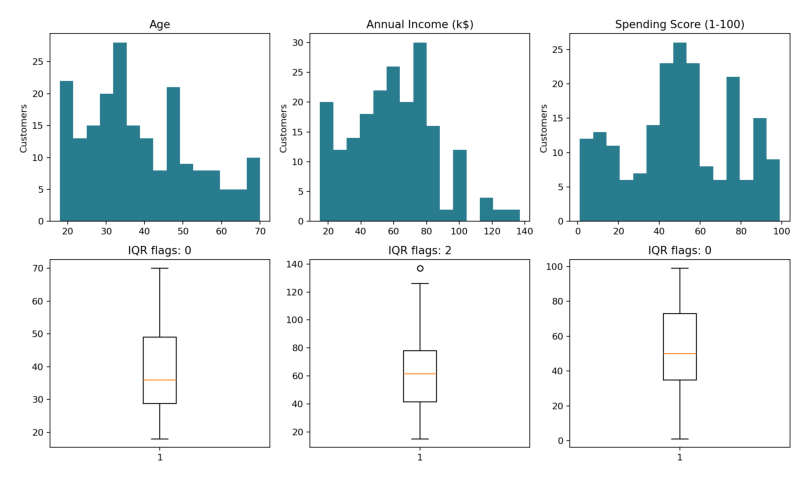

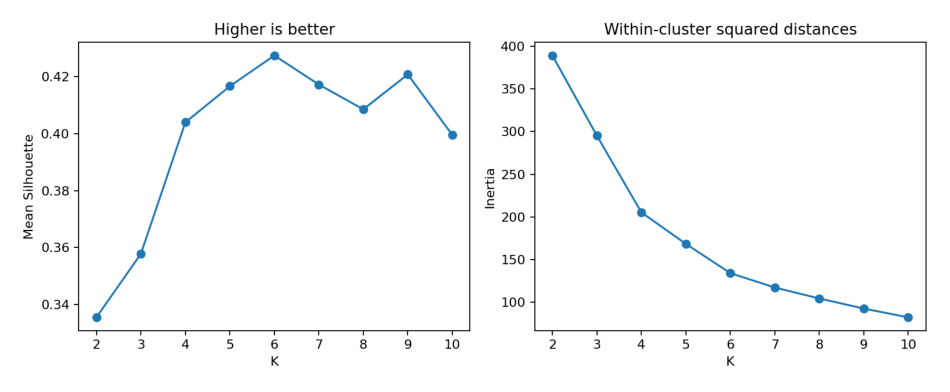

In [3]:
import matplotlib.pyplot as plt
for name in ["eda_overview.png", "silhouette_by_k.png"]:
    plt.figure(figsize=(12,6))
    plt.imshow(plt.imread(run / "figures" / name))
    plt.axis("off")
    plt.show()


## Biểu đồ 3D tương tác

Các trục dùng đơn vị gốc. Màu cụm được học trong không gian chuẩn hóa. Biểu đồ có thể xoay và xem CustomerID.

In [4]:
customers = pd.read_csv(run / "customer_clusters.csv")
figure = plot_clusters(customers, config["data"]["features"], config["data"]["id_column"],
                       run / "figures/customer_clusters_3d.html")
figure.show()


<Interactive customer clustering — standalone HTML also saved in run/figures>

## Diễn giải và kết luận

So sánh trung bình cụm với toàn bộ dữ liệu. Các tên thấp/cao chỉ là mô tả tương đối. Silhouette mô tả mức tách cụm, chưa xác nhận hiệu quả một chiến dịch marketing.

In [5]:
features = config["data"]["features"]
overall = raw[features].mean()
for row in profiles.to_dict(orient="records"):
    descriptions = []
    for feature in features:
        value = row[feature + "_mean"]
        relative = "cao hơn" if value > overall[feature] else "thấp hơn hoặc bằng"
        descriptions.append(f"{feature} trung bình {value:.1f}, {relative} toàn bộ mẫu")
    print(f"Cụm {row['cluster']}, {row['customer_count']} khách: " + "; ".join(descriptions))
print("Kết quả:", run)


Cụm 0, 33 khách: Age trung bình 41.9, cao hơn toàn bộ mẫu; Annual Income (k$) trung bình 88.9, cao hơn toàn bộ mẫu; Spending Score (1-100) trung bình 17.0, thấp hơn hoặc bằng toàn bộ mẫu
Cụm 1, 45 khách: Age trung bình 56.3, cao hơn toàn bộ mẫu; Annual Income (k$) trung bình 54.3, thấp hơn hoặc bằng toàn bộ mẫu; Spending Score (1-100) trung bình 49.1, thấp hơn hoặc bằng toàn bộ mẫu
Cụm 2, 38 khách: Age trung bình 26.7, thấp hơn hoặc bằng toàn bộ mẫu; Annual Income (k$) trung bình 57.6, thấp hơn hoặc bằng toàn bộ mẫu; Spending Score (1-100) trung bình 47.8, thấp hơn hoặc bằng toàn bộ mẫu
Cụm 3, 39 khách: Age trung bình 32.7, thấp hơn hoặc bằng toàn bộ mẫu; Annual Income (k$) trung bình 86.5, cao hơn toàn bộ mẫu; Spending Score (1-100) trung bình 82.1, cao hơn toàn bộ mẫu
Cụm 4, 21 khách: Age trung bình 45.5, cao hơn toàn bộ mẫu; Annual Income (k$) trung bình 26.3, thấp hơn hoặc bằng toàn bộ mẫu; Spending Score (1-100) trung bình 19.4, thấp hơn hoặc bằng toàn bộ mẫu
Cụm 5, 24 khách: Age 